


# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

In [69]:
# Importe as bibliotecas
import pandas as pd
import numpy as np

In [70]:
# leia os conjuntos de dados em DataFrames
df_instacart_orders = pd.read_csv('instacart_orders.csv', sep =";")
df_products = pd.read_csv('products.csv',sep = ";")
df_aisles = pd.read_csv('aisles.csv',sep = ";")
df_departments = pd.read_csv('departments.csv',sep = ";")
df_order_products = pd.read_csv('order_products.csv',sep = ";")

In [71]:
print(df_instacart_orders.head(20))# imprima as informações sobre o DataFrame
df_instacart_orders.info()

    order_id  user_id  order_number  order_dow  order_hour_of_day  \
0    1515936   183418            11          6                 13   
1    1690866   163593             5          5                 12   
2    1454967    39980             4          5                 19   
3    1768857    82516            56          0                 20   
4    3007858   196724             2          4                 12   
5    1843871    20084             5          0                 11   
6    2511640   148233            40          3                  8   
7    2521283    97711             2          0                 18   
8    2266494    34954            40          5                 15   
9     446014    15356             2          4                  8   
10   1162566    43738            33          4                 11   
11    102585   191558            18          6                 16   
12   2276302   190167            21          1                 12   
13    782916    36310            3

In [72]:
print(df_products.head())# imprima as informações sobre o DataFrame
df_products.info()

   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt       104   
2           3               Robust Golden Unsweetened Oolong Tea        94   
3           4  Smart Ones Classic Favorites Mini Rigatoni Wit...        38   
4           5                          Green Chile Anytime Sauce         5   

   department_id  
0             19  
1             13  
2              7  
3              1  
4             13  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [73]:
print(df_aisles.head())# imprima as informações sobre o DataFrame
df_aisles.info()

   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [74]:
print(df_departments)# imprima as informações sobre o DataFrame
df_departments.info()

    department_id       department
0               1           frozen
1               2            other
2               3           bakery
3               4          produce
4               5          alcohol
5               6    international
6               7        beverages
7               8             pets
8               9  dry goods pasta
9              10             bulk
10             11    personal care
11             12     meat seafood
12             13           pantry
13             14        breakfast
14             15     canned goods
15             16       dairy eggs
16             17        household
17             18           babies
18             19           snacks
19             20             deli
20             21          missing
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 

In [75]:
print(df_order_products.head())# imprima as informações sobre o DataFrame
df_order_products.info(show_counts=True)

   order_id  product_id  add_to_cart_order  reordered
0   2141543       11440               17.0          0
1    567889        1560                1.0          1
2   2261212       26683                1.0          1
3    491251        8670               35.0          1
4   2571142        1940                5.0          1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 1. Visão geral dos dados

Os dados vieram em CSV porém com o separador ponto e vírgula, então usei o SEP ";" para que pudesse ler corretamente cada arquivo.
o arquivo *df_instacart* tem os tipos de dados corretos para todas as colunas, menos para a coluna 'days_since_prior_order' que tem o tipo float pois tem valores nulos e esses valores são nulos pois não tem ainda 1 dia que o cliente fez seu pedido anterior.
o arquivo *df_products* tem valores nulos que correspondem todos ao mesmo aisle_id e department_id e tem os tipos de dados corretos
o arquivo *df_aisles* não tem valores nulos e tem os tipos de dados corretos
o arquivo *df_departments* não tem valores nulos e tem os tipos de dados corretos
o arquivo *df_order_products* tem os tipos de dados corretos para todas as colunas, menos para a coluna 'add_to_cart_order' que tem o tipo float pois tem valores nulos

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

Verificar os dados duplicados de cada DataFrame, removê-los de for o caso
Verificar os dados ausentes e preenche-los se for o caso.

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [76]:
# Primeiro, identifique as duplicadas
linhas_duplicadas = df_instacart_orders.duplicated(keep=False)
print(f"Número de linhas duplicadas: {linhas_duplicadas.sum()}")
print()
# Depois, filtre para ver essas linhas
df_duplicadas = df_instacart_orders[linhas_duplicadas]
print(df_duplicadas.head(20))

Número de linhas duplicadas: 30

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
30371    1918001   188546            14          3                  2   
99462     794638    50898            24          3                  2   
119251    408114    68324             4          3                  2   
142258   2845099    31189            11          3                  2   
145574    794638    50898            24          3                  2   
164581   1112182   202304            84          3                  2   
200059   1782114   106752             1          3                  2   
204042   2125197    14050            48          3                  2   
215294   2160484   107525            16          3                  2   
223105   2160484   107525            16          3                  2   
230807   1918001   188546            14          3                  2   
242618   1021560    53767             3          3                  2   
250626    467134  

Há linhas duplicadas? Se sim, o que elas têm em comum?

Sim, há 30 linhas duplicadas e todas tem o mesmo dia de semana e hora do dia em comum, que é quarta-feira ás 2 horas da manhã.

In [77]:
# Com base nas suas conclusões,
# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras
pedidos_2h_quarta = df_instacart_orders[(df_instacart_orders['order_hour_of_day'] == 2) & (df_instacart_orders['order_dow'] == 3)]
print(f"Número de pedidos às 2h nas quartas-feiras: {len(pedidos_2h_quarta)}")
print(pedidos_2h_quarta.head())


Número de pedidos às 2h nas quartas-feiras: 121
       order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838    2766110   162084            41          3                  2   
5156    2190225   138285            18          3                  2   
15506    553049    58599            13          3                  2   
18420    382357   120200            19          3                  2   
24691    690242    77357             2          3                  2   

       days_since_prior_order  
4838                     16.0  
5156                     11.0  
15506                     7.0  
18420                    11.0  
24691                     9.0  


O que esse resultado quer dizer?

Que na quarta feira ás 2h teve 121 pedidos, porém desses 121 somente 30 estão duplicados.

In [78]:
# Remova pedidos duplicados

df_sem_duplicates = df_instacart_orders.drop_duplicates()
print(f"Linhas antes: {len(df_instacart_orders)}")
print(f"Linhas depois: {len(df_sem_duplicates)}")



Linhas antes: 478967
Linhas depois: 478952


In [79]:
# Verifique as linhas duplicadas mais uma vez
print(f"Duplicados restantes: {df_sem_duplicates.duplicated().sum()}")

Duplicados restantes: 0


In [80]:
# Verifique novamente apenas os IDs de pedidos duplicados
ids_duplicados = df_instacart_orders[df_instacart_orders.duplicated('order_id', keep=False)]['order_id'].unique() # Aqui eu identifiquei quais order_ids estão duplicados
linhas_duplicadas = df_instacart_orders[df_instacart_orders['order_id'].isin(ids_duplicados)] #Aqui eu filtrei o DataFrame para mostrar apenas essas linhas
print(f"Encontrados {len(ids_duplicados)} order_ids duplicados:") # Aqui eu estou imprimindo a quantidade de id´s duplicados
print(linhas_duplicadas.sort_values('order_id')) #Aqui eu estou imprimindo o dataframe filtrada por ordem do Id

Encontrados 15 order_ids duplicados:
        order_id  user_id  order_number  order_dow  order_hour_of_day  \
354993    391768    57671            19          3                  2   
371905    391768    57671            19          3                  2   
119251    408114    68324             4          3                  2   
321100    408114    68324             4          3                  2   
394347    467134    63189            21          3                  2   
250626    467134    63189            21          3                  2   
145574    794638    50898            24          3                  2   
99462     794638    50898            24          3                  2   
242618   1021560    53767             3          3                  2   
311713   1021560    53767             3          3                  2   
273805   1112182   202304            84          3                  2   
164581   1112182   202304            84          3                  2   
314427   12867

Descreva brevemente suas conclusões e o que você fez com elas.

Na análise vimos de dos 121 pedidos feitos na quarta-feira ás 2 da manhã, apenas 30 ordens estavam duplicadas, verificamos que pertenciam ao mesmo user_id, o que significa que eram realmente linhas duplicadas e removemos as 15 linhas que estavam duplicando do dataframe.

### DataFrame `products`

In [81]:
# Verifique se há linhas completamente duplicadas
df_products[df_products.duplicated()]

,product_id,product_name,aisle_id,department_id


In [82]:
# Verifique apenas IDs dos produtos duplicados
df_products[df_products.duplicated(subset=['product_id', 'aisle_id','department_id'])]

,product_id,product_name,aisle_id,department_id


In [83]:
# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)
df_products['product_name'] = df_products['product_name'].str.lower()
df_products[df_products.duplicated()]

,product_id,product_name,aisle_id,department_id


In [84]:
# Verifique os nomes de produtos duplicados que não estão faltando
df_products['product_name'] = df_products['product_name'].notna()
df_products[df_products.duplicated()]

,product_id,product_name,aisle_id,department_id


Quando verificamos o Dataframe Products vemos que ele não tem valores duplicados, nem Id´s duplicados, nem os nomes de produtos, mesmo convertendo para minusculo.

### DataFrame `departments`

In [85]:
# Verifique se há linhas completamente duplicadas
df_departments[df_departments.duplicated()]

,department_id,department


In [86]:
# Verifique apenas se há IDs dos produtos duplicados
df_departments[df_departments.duplicated(subset=['department_id'])]

,department_id,department


Quando verificamos o Dataframe Departments vemos que ele não tem valores duplicados, nem Id´s duplicados.

### DataFrame `aisles`

In [87]:
# Verifique se há linhas completamente duplicadas

df_aisles[df_aisles.duplicated()]

,aisle_id,aisle


In [88]:
# Verifique apenas se há IDs dos produtos duplicados

df_aisles[df_aisles.duplicated(subset=['aisle_id'])]

,aisle_id,aisle


Quando verificamos o Dataframe Aisles vemos que ele não tem valores duplicados, nem Id´s duplicados.

### DataFrame `order_products`

In [89]:
# Verifique se há linhas completamente duplicadas
df_order_products[df_order_products.duplicated()]

,order_id,product_id,add_to_cart_order,reordered


In [90]:
# Verifique mais uma vez se há outros casos complicados de duplicados
df_order_products[df_order_products.duplicated(subset=['order_id','product_id'])]

,order_id,product_id,add_to_cart_order,reordered


Quando verificamos o Dataframe order_products vemos que ele não tem valores duplicados, nem outros casos de dados duplicados.

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [91]:
# Encontre valores ausentes na coluna 'product_name'
df_products = pd.read_csv('products.csv', sep=";")

Products_ausentes=df_products[df_products['product_name'].isnull()]

print(f"Número de produtos ausentes: {len(Products_ausentes)}")
print(Products_ausentes.head())

Número de produtos ausentes: 1258
     product_id product_name  aisle_id  department_id
37           38          NaN       100             21
71           72          NaN       100             21
109         110          NaN       100             21
296         297          NaN       100             21
416         417          NaN       100             21


Verifiquei que no Data Frame Products, na coluna Product Name há 1258 linhas com valores ausentes "NaN" e que as mesmas tem em comum a  coluna aisle_id = 100 e depatment_id = 21.

In [92]:
# Todos os nomes de produtos ausentes estão associados com o corredor de ID 100?
produtos_aisle_100 = Products_ausentes['aisle_id'] == 100
print(produtos_aisle_100.value_counts())

aisle_id
True    1258
Name: count, dtype: int64


Sim, todos os nomes de produtos ausentes estão associados com o corredor de ID100.

In [93]:
# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?
produtos_dep_21 = Products_ausentes['department_id'] == 21
print(produtos_dep_21.value_counts())

department_id
True    1258
Name: count, dtype: int64


Sim, todos os nomes de produtos ausentes estão associados com o departamento de ID 21.

In [94]:
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.
aisle100 = df_aisles[df_aisles['aisle_id'] == 100]
print(aisle100)
dep_21 = df_departments[df_departments['department_id'] == 21]
print(dep_21)

    aisle_id    aisle
99       100  missing
    department_id department
20             21    missing


Descreva brevemente suas conclusões.

Com esse resultado com os nomes "missing", concluo que os produtos com nome ausente foram colocados em um corredor e departamento criados especificamente para dados faltantes.

In [95]:
# Preencha nomes de produtos ausentes com 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')

produtos_unknown = df_products[df_products['product_name'] == 'Unknown']
print(f"Primeiros 5 produtos preenchidos:")
print(produtos_unknown.head())

Products_ausentes=df_products[df_products['product_name'].isnull()]
print(f"Número de produtos ausentes: {len(Products_ausentes)}")
print(Products_ausentes.head())




Primeiros 5 produtos preenchidos:
     product_id product_name  aisle_id  department_id
37           38      Unknown       100             21
71           72      Unknown       100             21
109         110      Unknown       100             21
296         297      Unknown       100             21
416         417      Unknown       100             21
Número de produtos ausentes: 0
Empty DataFrame
Columns: [product_id, product_name, aisle_id, department_id]
Index: []


Preenchemos os dados de product name que estavam ausente com o valor string "Unknown"

### DataFrame `orders`

In [96]:
# Encontre os valores ausentes
Valores_ausentes=df_instacart_orders[df_instacart_orders['days_since_prior_order'].isnull()]
print(f"Número de valores ausentes: {len(Valores_ausentes)}")
print(Valores_ausentes.head())

Número de valores ausentes: 28819
     order_id  user_id  order_number  order_dow  order_hour_of_day  \
28     133707   182261             1          3                 10   
96     787445    25685             1          6                 18   
100    294410   111449             1          0                 19   
103   2869915   123958             1          4                 16   
104   2521921    42286             1          3                 18   

     days_since_prior_order  
28                      NaN  
96                      NaN  
100                     NaN  
103                     NaN  
104                     NaN  


In [97]:
# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?
nao_primeiro_pedido = df_instacart_orders['order_number'] != 1
va_pedidos = df_instacart_orders[nao_primeiro_pedido & df_instacart_orders['order_number'].isna()]
va_pedidos = df_instacart_orders[df_instacart_orders['order_number'].isna()]
print(f"Número de valores ausentes (clientes que não estão no 1º pedido): {len(va_pedidos)}")
print(va_pedidos.head())

Número de valores ausentes (clientes que não estão no 1º pedido): 0
Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


Os valores ausentes estão todos para os clientes que estão fazendo o seu primeiro pedido, concluo que esses valores estão ausentes pois não houve ainda um proximo pedido.

### DataFrame `order_products`

In [98]:
# Encontre os valores ausentes
Valores_ausentes=df_order_products[df_order_products['add_to_cart_order'].isnull()]
print(f"Número de valores ausentes: {len(Valores_ausentes)}")
print(Valores_ausentes.head())

Número de valores ausentes: 836
       order_id  product_id  add_to_cart_order  reordered
737     2449164        5068                NaN          0
9926    1968313       43867                NaN          0
14394   2926893       11688                NaN          0
16418   1717990        4142                NaN          0
30114   1959075       42828                NaN          1


In [99]:
# Quais são os valores mínimo e máximo dessa coluna?
valor_min = df_order_products['add_to_cart_order'].min()
valor_max = df_order_products['add_to_cart_order'].max()
print(f"Valor mínimo: {valor_min}")
print(f"Valor máximo: {valor_max}")

Valor mínimo: 1.0
Valor máximo: 64.0


A maior parte dos dados está consistente: todos os valores não nulos variam entre 1 e 64, que é razoável para a ordem de adição ao carrinho.
Os 836 registros ausentes representam pedidos onde não foi registrado em qual posição o item entrou no carrinho.
Esses NaN podem ter algumas causas: erro no registro do dado,importação incompleta.

In [100]:
# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'
valores_ausentes = df_order_products[df_order_products['add_to_cart_order'].isna()] ## Filtra os registros com add_to_cart_order ausente
pedidos_com_ausentes = valores_ausentes['order_id'].unique() ## Pega os IDs únicos dos pedidos afetados
print(f"Número de pedidos com pelo menos um valor ausente: {len(pedidos_com_ausentes)}")

Número de pedidos com pelo menos um valor ausente: 70


In [101]:
# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
valores_ausentes = df_order_products[df_order_products['add_to_cart_order'].isna()] #Filtra apenas as linhas com add_to_cart_order ausente
produtos_por_pedido = valores_ausentes.groupby('order_id').size() #Conta quantos produtos com valores ausentes cada pedido tem
produtos_mais_64 = produtos_por_pedido[produtos_por_pedido > 64] #Filtra apenas os pedidos que têm mais de 64 produtos ausentes
print(f"Pedidos com valores ausentes que têm mais de 64 produtos: {len(produtos_mais_64)}")
print(f"Total de pedidos com valores ausentes: {len(pedidos_com_ausentes)}")

# Agrupe os pedidos com dados ausentes por ID de pedido
pedidos_ausentes_ID = produtos_por_pedido.groupby('order_id').size() #Uma série com order_id e quantidade de produtos ausentes
print(f"Número de pedidos ausente por ID: {len(pedidos_ausentes_ID)}")
print(pedidos_ausentes_ID.head(10))
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem
contagem_por_pedido = df_order_products.groupby('order_id')['product_id'].count() # Para contar produtos por pedido
valor_minimo = contagem_por_pedido.min() # Para encontrar o mínimo
print(f"Valor mínimo de produtos por pedido: {valor_minimo}")

Pedidos com valores ausentes que têm mais de 64 produtos: 0
Total de pedidos com valores ausentes: 70
Número de pedidos ausente por ID: 70
order_id
9310      1
61355     1
102236    1
129627    1
165801    1
171934    1
180546    1
264710    1
293169    1
388234    1
dtype: int64
Valor mínimo de produtos por pedido: 1


No Dataframe order_products temos 70 id´s unicos com pelo menos um valor ausente, desses pedidos com valor ausente nenhum deles tem mais de 64 produtos e tem pelo menos 1 item em cada pedido

In [102]:
# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype(int)
print(df_order_products['add_to_cart_order'].value_counts().sort_index().tail())

add_to_cart_order
61     114
62      98
63      87
64      75
999    836
Name: count, dtype: int64


Quando substituimos os valores ausentes de coluna add to cart order por 999, vemos que foram subsitituidos 836 numeros, ou seja todos os ausentes que encontramos acima.

## Conclusões

Todos os dados duplicados foram identificamos e removidos e os valores ausentes identificamos e preenchidos.

# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:

# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [103]:
print("Valores mínimo e máximo de order_hour_of_day:")
print(df_instacart_orders['order_hour_of_day'].min(), df_instacart_orders['order_hour_of_day'].max())

print("Valores mínimo e máximo de order_dow:")
print(df_instacart_orders['order_dow'].min(), df_instacart_orders['order_dow'].max())


Valores mínimo e máximo de order_hour_of_day:
0 23
Valores mínimo e máximo de order_dow:
0 6


para a coluna order hour os day as variações de 0 a 23, bate com os valores correspondentes a um dia 24h
para a coluna order row os valores batem com os dias da semana, segundda a sexta (0 a 6), sendo domingo = 0.

### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

order_hour_of_day
0      3180
1      1763
2      1004
3       770
4       765
5      1371
6      4215
7     13043
8     25024
9     35896
10    40578
11    40032
12    38034
13    39007
14    39631
15    39789
16    38112
17    31930
18    25510
19    19547
20    14624
21    11019
22     8512
23     5611
Name: count, dtype: int64


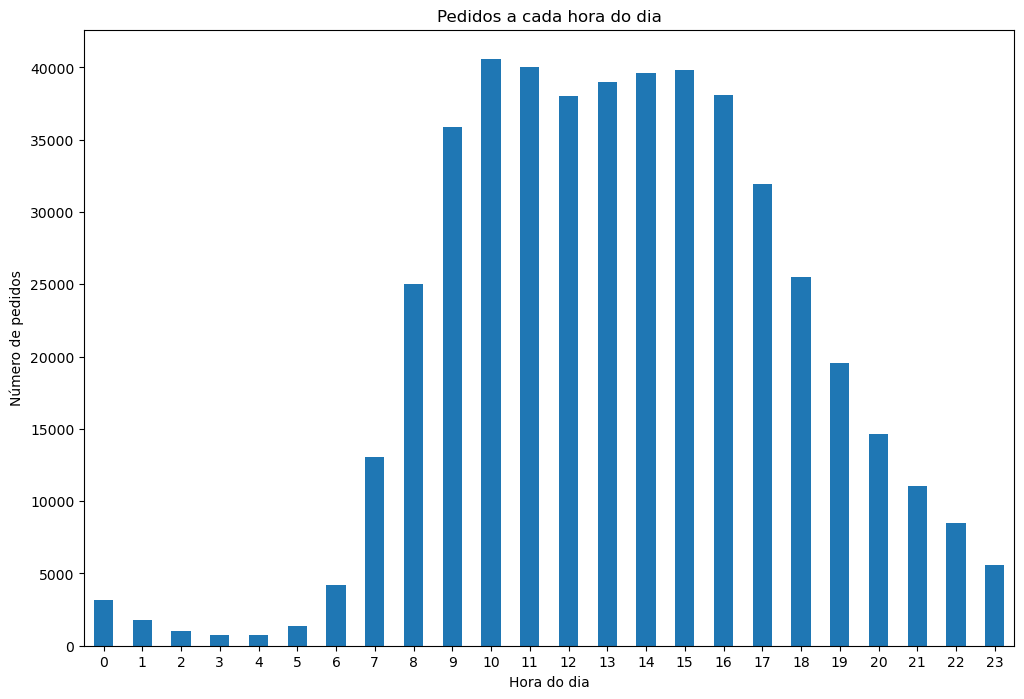

In [104]:
from matplotlib import pyplot as plt

pedidos_por_hora = df_instacart_orders['order_hour_of_day'].value_counts().sort_index()
print(pedidos_por_hora)

pedidos_por_hora.plot(kind='bar', figsize=(12,8))
plt.title('Pedidos a cada hora do dia')
plt.xlabel('Hora do dia')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=0)
plt.show()

Vemos que temos um pico de pessoas as 10 horas da manhã com 40.578 pessoas , até as 16 horas com 38.112 pessoas, depois esse valor vai caindo.

### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

order_dow
0    84090
1    82185
2    65833
3    60912
4    59810
5    63488
6    62649
Name: count, dtype: int64


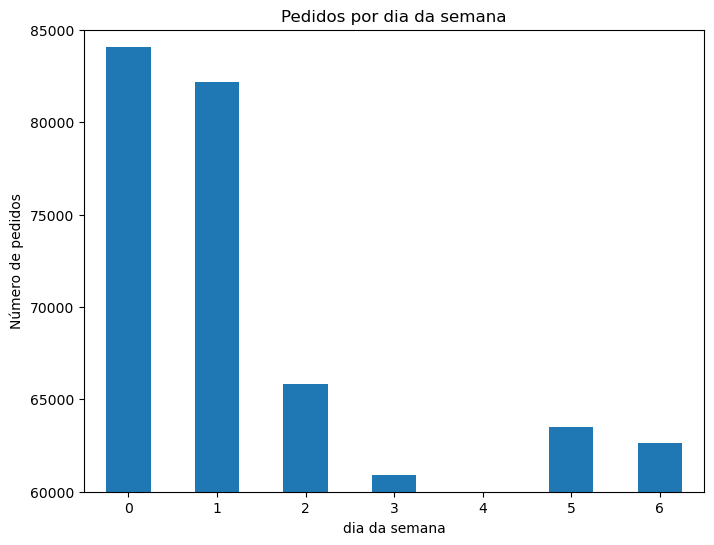

In [105]:
import matplotlib.pyplot as plt

pedidos_por_dia = df_instacart_orders['order_dow'].value_counts().sort_index()
print(pedidos_por_dia)

pedidos_por_dia.plot(kind='bar', figsize=(8,6))
plt.title('Pedidos por dia da semana')
plt.xlabel('dia da semana')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=0)
plt.ylim([60000,85000]) 
plt.show()


Os dias em que as pessoas mais compram produtos alimentícios são domingo, e depois segunda feira.

### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

days_since_prior_order
0.0      9589
1.0     20179
2.0     27141
3.0     30225
4.0     31007
5.0     30096
6.0     33931
7.0     44579
8.0     25361
9.0     16754
10.0    13310
11.0    11467
12.0    10658
13.0    11737
14.0    13992
15.0     9416
16.0     6588
17.0     5498
18.0     4972
19.0     4939
20.0     5302
21.0     6448
22.0     4514
23.0     3337
24.0     3015
25.0     2711
26.0     2640
27.0     2986
28.0     3745
29.0     2673
30.0    51338
Name: count, dtype: int64


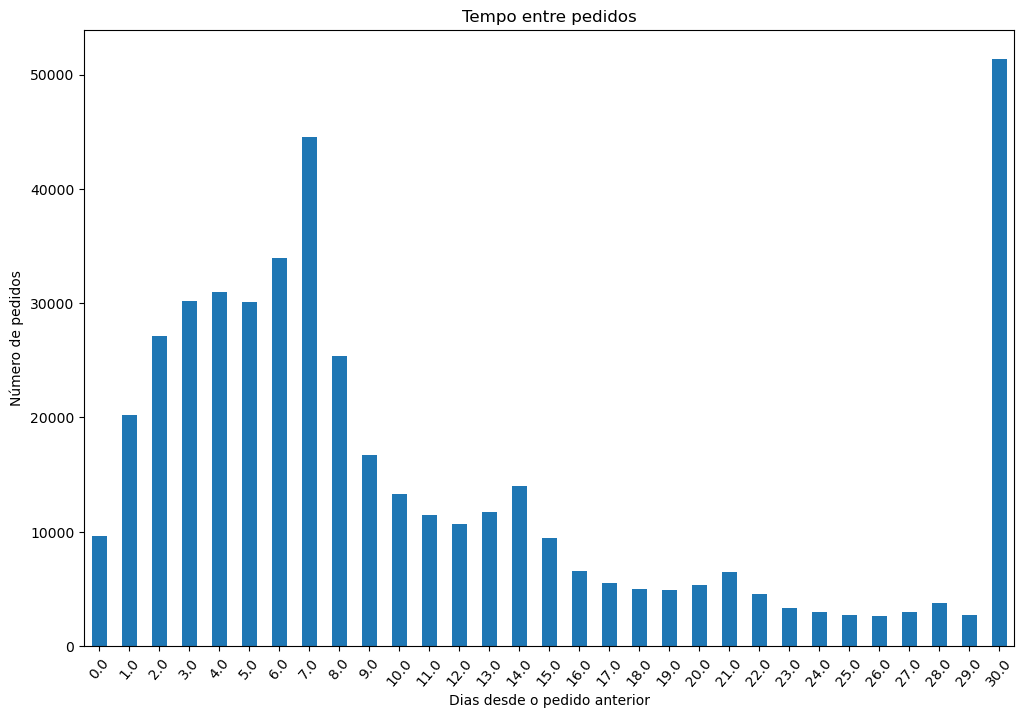

In [106]:
import matplotlib.pyplot as plt

tempo_pedidos = df_instacart_orders['days_since_prior_order'].value_counts().sort_index()
print(tempo_pedidos)

tempo_pedidos.plot(kind='bar', figsize=(12,8))
plt.title('Tempo entre pedidos')
plt.xlabel('Dias desde o pedido anterior')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=50)
plt.show()

Na análise pelo gráfico pode verificar que temos um pico entre os 7 dias (44579) e aos 30 dias (51338)

# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

order_hour_of_day
0      373
1      215
2      121
3      101
4      108
5      170
6      643
7     1732
8     3125
9     4490
10    5026
11    5004
12    4688
13    4674
14    4774
15    5163
16    4976
17    4175
18    3463
19    2652
20    1917
21    1450
22    1154
23     718
Name: count, dtype: int64
order_hour_of_day
0      464
1      254
2      177
3      125
4      118
5      161
6      451
7     1619
8     3246
9     4311
10    4919
11    5116
12    5132
13    5323
14    5375
15    5188
16    5029
17    4295
18    3338
19    2610
20    1847
21    1473
22    1185
23     893
Name: count, dtype: int64


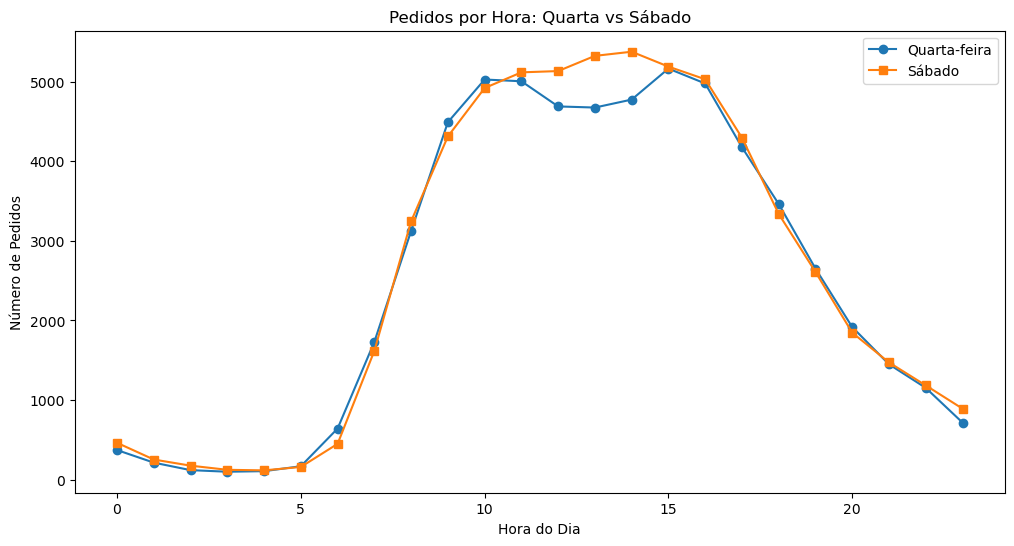

In [107]:

import matplotlib.pyplot as plt

ordens_quarta = df_instacart_orders[df_instacart_orders['order_dow'] == 3]
ordens_sabado = df_instacart_orders[df_instacart_orders['order_dow'] == 6]

horas_quarta_count = ordens_quarta['order_hour_of_day'].value_counts().sort_index()
horas_sabado_count = ordens_sabado['order_hour_of_day'].value_counts().sort_index()
print(horas_quarta_count)
print(horas_sabado_count)

plt.figure(figsize=(12, 6))
plt.plot(horas_quarta_count.index, horas_quarta_count.values, label='Quarta-feira', marker='o')
plt.plot(horas_sabado_count.index, horas_sabado_count.values, label='Sábado', marker='s')
plt.title('Pedidos por Hora: Quarta vs Sábado')
plt.xlabel('Hora do Dia')
plt.ylabel('Número de Pedidos')
plt.legend()
plt.show()



Eu criei um gráfico de linhas, pois achei a análise mais limpa de ser fazer , achei que com gráfico de barras ficou muito poluido.
Pode-se ver que o número de pedidos entre quarta e sabado são parecidos, ambos tem um ápice as 10 horas da manhã, porem no sábado esse valor aumenta e começa a decair a partir das 15 hs, já na quarta ele cai e tem um outro pico as quinze horas (15 hs).

### [B2] Qual é a distribuição do número de pedidos por cliente?

count
1     55355
2     36508
3     21548
4     13498
5      8778
6      6012
7      4240
8      3016
9      2153
10     1646
11     1308
12      948
13      701
14      514
15      437
16      263
17      184
18      121
19       85
20       52
21       22
22       23
23       19
24        3
25        1
26        1
28        1
Name: count, dtype: int64


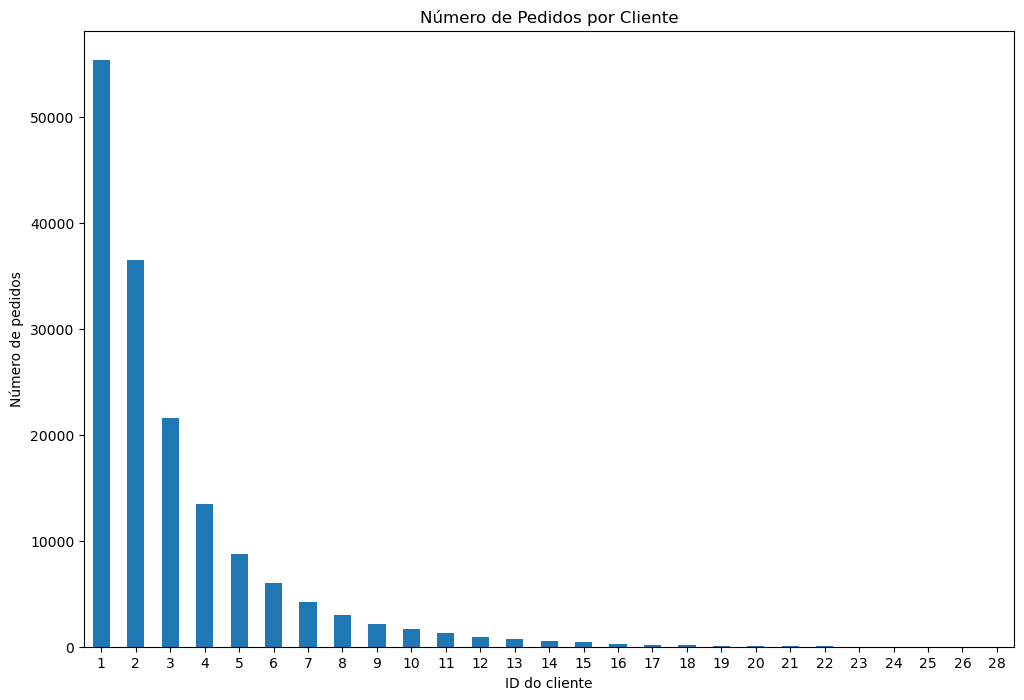

In [108]:
import matplotlib.pyplot as plt

num_clientes = df_instacart_orders['user_id'].value_counts().sort_index()# Primeiro, conte pedidos por cliente
distribuicao_pedidos = num_clientes.value_counts().sort_index() # Depois, conte quantos clientes fizeram cada quantidade de pedidos
print(distribuicao_pedidos)

distribuicao_pedidos.plot(kind='bar', figsize=(12,8))
plt.title('Número de Pedidos por Cliente')
plt.xlabel('ID do cliente')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=0)
plt.show()

A maior parte dos clientes fez somente 1 pedido.

### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

    product_id              product_name  count
0        24852                    Banana  66050
1        13176    Bag of Organic Bananas  53297
2        21137      Organic Strawberries  37039
3        21903      Organic Baby Spinach  33971
4        47209      Organic Hass Avocado  29773
5        47766           Organic Avocado  24689
6        47626               Large Lemon  21495
7        16797              Strawberries  20018
8        26209                     Limes  19690
9        27845        Organic Whole Milk  19600
10       27966       Organic Raspberries  19197
11       22935      Organic Yellow Onion  15898
12       24964            Organic Garlic  15292
13       45007          Organic Zucchini  14584
14       39275       Organic Blueberries  13879
15       49683            Cucumber Kirby  13675
16       28204        Organic Fuji Apple  12544
17        5876             Organic Lemon  12232
18        8277  Apple Honeycrisp Organic  11993
19       40706    Organic Grape Tomatoes

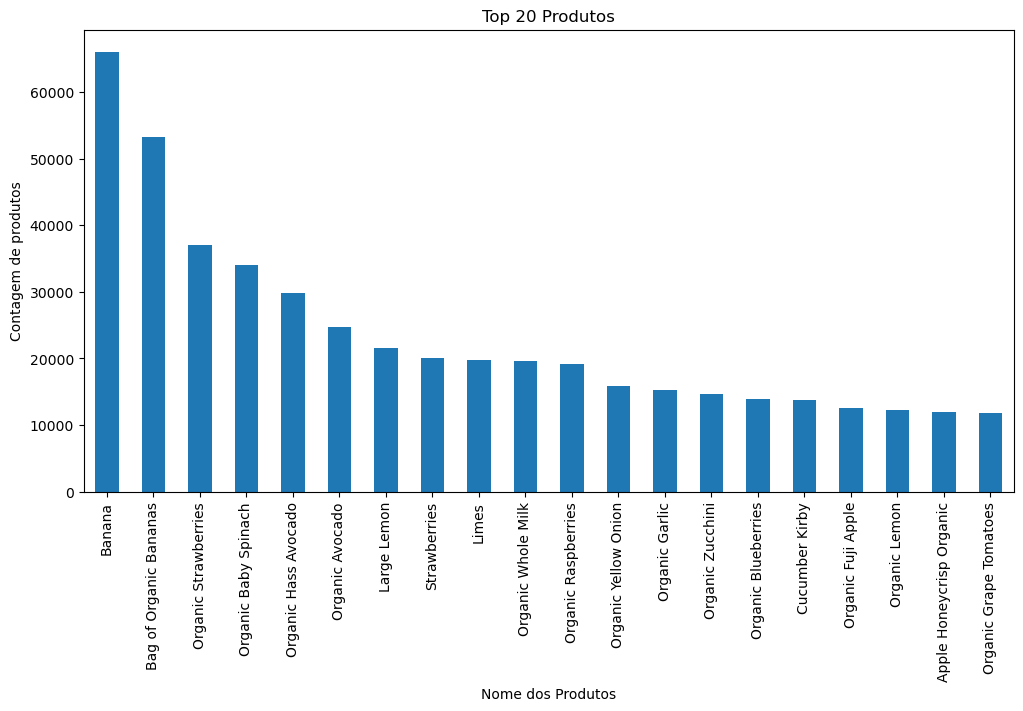

In [109]:
# 1. Agrupa por ID e nome de produto
# 2. Conta quantos pedidos (order_id) cada par (ID, nome) tem
# 3. Ordena do maior para o menor
# 4. Seleciona os 20 primeiros
# 5. Volta os índices a colunas normais

merged_data = df_order_products.merge(df_products, on='product_id') # Primeiro, junte as tabelas order_products e products

top_20 =(
    merged_data
    .groupby(['product_id', 'product_name'])['order_id']
    .size()
    .sort_values(ascending = False)
    .head(20)
    .reset_index(name = 'count')
)
print(top_20)

top_20.plot(x='product_name',
        y = 'count',
        kind='bar',
        title='Top 20 Produtos',
        xlabel='Nome dos Produtos',
        ylabel='Contagem de produtos',
        figsize = [12,6],
        legend = False,
        rot = 90
        )

plt.show()

O produto mais popular é a banana e a bag de bananas

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

product_id
1     21847
2     26292
3     29046
4     31054
5     31923
6     31698
7     30822
8     28539
9     25742
10    23248
Name: count, dtype: int64
product_id
86     3
87     1
91     2
92     2
95     2
98     1
104    1
108    1
115    1
127    1
Name: count, dtype: int64


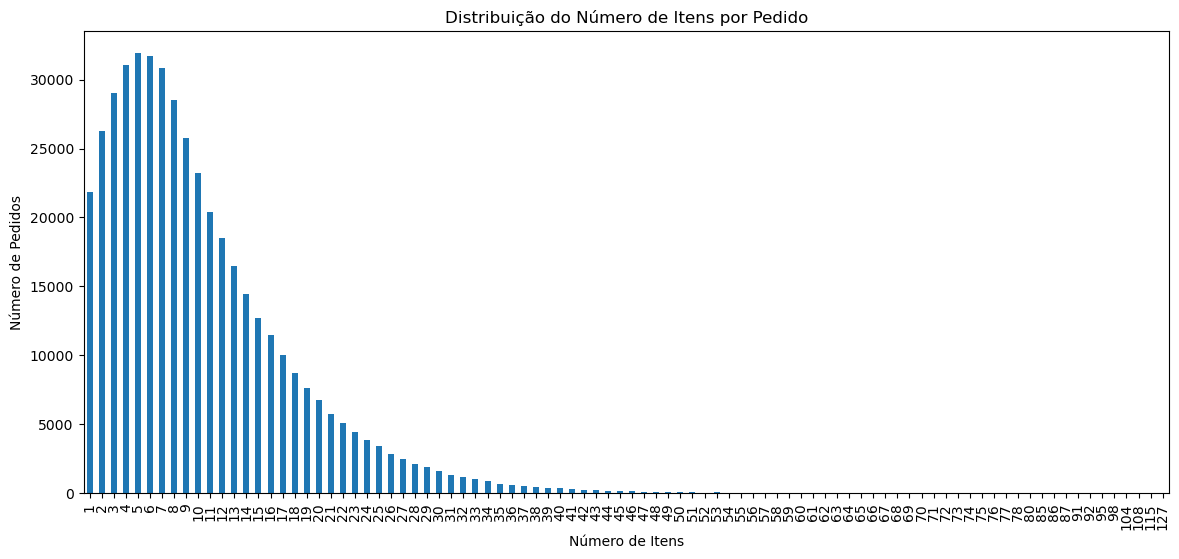

In [110]:

itens_por_pedido = df_order_products.groupby('order_id')['product_id'].nunique()
#print(itens_por_pedido)
distribuicao_itens = itens_por_pedido.value_counts().sort_index()
print(distribuicao_itens.head(10))
print(distribuicao_itens.tail(10))


# Faça um gráfico

distribuicao_itens.plot(kind='bar', figsize=(14, 6))
plt.title('Distribuição do Número de Itens por Pedido')
plt.xlabel('Número de Itens')
plt.ylabel('Número de Pedidos')
plt.xticks(rotation=90)  
plt.show()

Normalmente as pessoas compram aproximadamente 6 itens por pedido.

### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

    product_id              product_name  count
0        24852                    Banana  55763
1        13176    Bag of Organic Bananas  44450
2        21137      Organic Strawberries  28639
3        21903      Organic Baby Spinach  26233
4        47209      Organic Hass Avocado  23629
5        47766           Organic Avocado  18743
6        27845        Organic Whole Milk  16251
7        47626               Large Lemon  15044
8        27966       Organic Raspberries  14748
9        16797              Strawberries  13945
10       26209                     Limes  13327
11       22935      Organic Yellow Onion  11145
12       24964            Organic Garlic  10411
13       45007          Organic Zucchini  10076
14       49683            Cucumber Kirby   9538
15       28204        Organic Fuji Apple   8989
16        8277  Apple Honeycrisp Organic   8836
17       39275       Organic Blueberries   8799
18        5876             Organic Lemon   8412
19       49235       Organic Half & Half

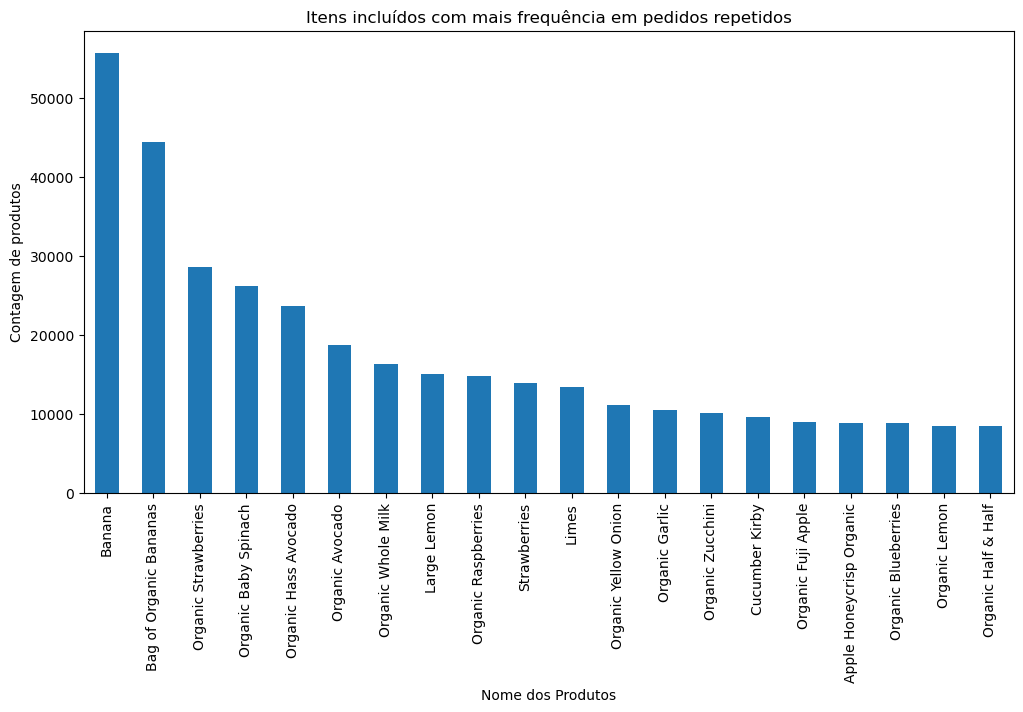

In [111]:

merged_data = df_order_products.merge(df_products, on='product_id') # Primeiro, junte as tabelas order_products e products

top_20_principais =(
    merged_data[merged_data['reordered'] == 1]  # Apenas pedidos repetidos
    .groupby(['product_id', 'product_name'])    # Agrupa por produto
    .size()                                     # Conta quantas vezes aparece
    .sort_values(ascending = False)             # Ordena do maior para menor
    .head(20)                                   # Pega os top 20
    .reset_index(name = 'count')                # Transforma em DataFrame
)
print(top_20_principais)

top_20_principais.plot(x='product_name',
        y = 'count',
        kind='bar',
        title='Itens incluídos com mais frequência em pedidos repetidos',
        xlabel='Nome dos Produtos',
        ylabel='Contagem de produtos',
        figsize = [12,6],
        legend = False,
        rot = 90
        )

plt.show()


Os itens compradados com mais frequencia em pedidos repetidos são: Banana e bag de bananas

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [118]:
# Realiza a junção dos dataframes 'order_products' e 'products' com base em uma chave comum
df_merge = df_order_products.merge(df_products, on='product_id')

# Calcula a taxa de reordenação (média de 'reordered') para cada produto, agrupando pelo 'product_id' e 'product_name'
reorder_rate = df_merge.groupby(['product_id', 'product_name'])['reordered'].mean()

# Exibe a taxa de reordenação calculada para cada produto
reorder_rate


product_id  product_name                                                     
1           Chocolate Sandwich Cookies                                           0.564286
2           All-Seasons Salt                                                     0.000000
3           Robust Golden Unsweetened Oolong Tea                                 0.738095
4           Smart Ones Classic Favorites Mini Rigatoni With Vodka Cream Sauce    0.510204
7           Pure Coconut Water With Orange                                       0.500000
                                                                                   ...   
49690       HIGH PERFORMANCE ENERGY DRINK                                        0.800000
49691       ORIGINAL PANCAKE & WAFFLE MIX                                        0.430556
49692       ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR                      0.416667
49693       SPRING WATER BODY WASH                                               0.440000
49694       BURRITO- S

In [119]:
df_order_products

,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17,0
1,567889,1560,1,1
2,2261212,26683,1,1
3,491251,8670,35,1
4,2571142,1940,5,1
...,...,...,...,...
4545002,577211,15290,12,1
4545003,1219554,21914,9,0
4545004,692640,47766,4,1
4545005,319435,691,8,1


Escreva suas conclusões aqui

### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [120]:
# Contar o número total de pedidos para cada cliente
total_pedidos_por_cliente = df_instacart_orders['user_id'].value_counts()

# Contar o número de pedidos repetidos para cada cliente
pedidos_repetidos_por_cliente = df_order_products[df_order_products['reordered'] == 1]['order_id'].value_counts()

# Calcular a proporção de pedidos repetidos para cada cliente
proporcao_pedidos_repetidos_cliente = pedidos_repetidos_por_cliente / total_pedidos_por_cliente

# Criar uma tabela com as colunas de ID do cliente e a proporção de pedidos repetidos
tabela_proporcao_repetidos_cliente = pd.DataFrame({
        'user_id': proporcao_pedidos_repetidos_cliente.index,
        'proporcao_repetidos': proporcao_pedidos_repetidos_cliente.values
    })

# Exibir a tabela
print(tabela_proporcao_repetidos_cliente)

        user_id  proporcao_repetidos
0             2                  NaN
1             4                  6.0
2             5                  NaN
3             6                  NaN
4             7                  NaN
...         ...                  ...
535073  3421013                  NaN
535074  3421018                  NaN
535075  3421034                  NaN
535076  3421053                  NaN
535077  3421071                  NaN

[535078 rows x 2 columns]


Escreva suas conclusões aqui

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [121]:
# Ordena os dados de pedidos por 'order_id' e 'add_to_cart_order' e seleciona o primeiro item de cada pedido
first_items = df_order_products.sort_values(by=['order_id', 'add_to_cart_order']).groupby('order_id').first().reset_index()

# Conta a frequência dos produtos que aparecem primeiro nos pedidos, pegando os 20 mais frequentes
first_item_counts = first_items['product_id'].value_counts().head(20).reset_index()
first_item_counts.columns = ['product_id', 'count']  # Renomeia as colunas para 'product_id' e 'count'

# Faz o merge com o dataframe de produtos para obter os nomes dos produtos
top_first_items = first_item_counts.merge(df_products, on='product_id')

# Exibe os 20 principais itens colocados nos carrinhos antes de todos os outros
print("Os 20 principais itens colocados nos carrinhos antes de todos os outros:")
print(top_first_items[['product_id', 'product_name', 'count']])

Os 20 principais itens colocados nos carrinhos antes de todos os outros:
    product_id                 product_name  count
0        24852                       Banana  15562
1        13176       Bag of Organic Bananas  11026
2        27845           Organic Whole Milk   4363
3        21137         Organic Strawberries   3946
4        47209         Organic Hass Avocado   3390
5        21903         Organic Baby Spinach   3336
6        47766              Organic Avocado   3044
7        19660                 Spring Water   2336
8        16797                 Strawberries   2308
9        27966          Organic Raspberries   2024
10       44632   Sparkling Water Grapefruit   1914
11       49235          Organic Half & Half   1797
12       47626                  Large Lemon   1737
13         196                         Soda   1733
14       38689     Organic Reduced Fat Milk   1397
15       26209                        Limes   1370
16       12341                Hass Avocados   1340
17       

Escreva suas conclusões aqui

# Conclusão geral do projeto:

Podemos passar para Instacart que a maioria dos clientes compram as quartas e domingos, entre as 10 e as 15 horas e gostam de comprar em sua maior partes, frutas, podendo assim fazer uma ação de promoção para frutas nesses dias e horários.